In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer, average_precision_score, log_loss
from xgboost import XGBClassifier
from scipy.stats import randint, uniform, loguniform
from lime.lime_tabular import LimeTabularExplainer

c:\Users\5agak\anaconda3\anaconda2\envs\survival\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_csv(Path('data','development_set.csv'))
excluded_columns = ['default', 'cv_fold', 'company_group_id']
X = data.drop(columns=excluded_columns)
y = data['default']

test_data = pd.read_csv(Path('data','test_holdout_set.csv'))
X_test = test_data.drop(columns=['default','company_group_id'])
y_test = test_data['default']
folds = data["cv_fold"]

In [3]:
object_columns = X.select_dtypes(include=["object"]).columns.tolist()

print("Liczba kolumn tekstowych:", len(object_columns))
print("\nKolumny tekstowe:")
print(object_columns)

Liczba kolumn tekstowych: 2

Kolumny tekstowe:
['schemat_wsk_bilans', 'schemat_wsk_rzis']


In [4]:
categorical_columns = [
    "schemat_wsk_bilans",
    "schemat_wsk_rzis"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

In [5]:
numeric_columns = X.select_dtypes(include=np.number).columns
inf_counts = np.isinf(X[numeric_columns]).sum()

print("Liczba wartości inf w poszczególnych kolumnach:")
print(inf_counts[inf_counts > 0])

Liczba wartości inf w poszczególnych kolumnach:
wsk_kapital_do_aktywa               8
wsk_plynnosc_biez_1               691
wsk_struktura_kap_wlasnego_s_2     69
dtype: int64


In [6]:
# Zamiana wartości nieskończonych na braki danych
X = X.replace([np.inf, -np.inf], np.nan)

In [7]:
missing_counts = X.isna().sum()

display(
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
)

wsk_plynnosc_biez_1               788
wsk_struktura_kap_wlasnego_s_2    102
wsk_kapital_do_aktywa              40
dtype: int64

In [8]:
# Wykorzystujemy istniejące foldy
cv = PredefinedSplit(test_fold=folds.to_numpy())

print("Liczba foldów:", cv.get_n_splits())

Liczba foldów: 5


In [9]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("xgboost", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ))
])

param_distributions = {
    "xgboost__n_estimators": randint(100, 501),
    "xgboost__max_depth": randint(2, 7),
    "xgboost__learning_rate": loguniform(0.01, 0.2),
    "xgboost__subsample": uniform(0.6, 0.4),
    "xgboost__colsample_bytree": uniform(0.6, 0.4),
    "xgboost__min_child_weight": randint(1, 11),
    "xgboost__reg_lambda": loguniform(0.1, 20),
    "xgboost__gamma": uniform(0, 2)
}

In [10]:
search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring={
        "AUC": "roc_auc",
        "PR_AUC": "average_precision",
        "Log_Loss": "neg_log_loss"
    },
    refit="AUC",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

search.fit(X, y)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'xgboost__colsample_bytree': <scipy.stats....001F0F5FFC5D0>, 'xgboost__gamma': <scipy.stats....001F0F5FFD850>, 'xgboost__learning_rate': <scipy.stats....001F0F5FF7B50>, 'xgboost__max_depth': <scipy.stats....001F0F5EA6510>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'AUC': 'roc_auc', 'Log_Loss': 'neg_log_loss', 'PR_AUC': 'average_precision'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'AUC'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters a

In [11]:
tuning_results = pd.DataFrame(search.cv_results_)

tuning_results = tuning_results.sort_values(
    by="mean_test_AUC",
    ascending=False
)

display(
    tuning_results[
        [
            "params",
            "mean_test_AUC",
            "std_test_AUC",
            "mean_test_PR_AUC",
            "mean_test_Log_Loss"
        ]
    ].head(10)
)

,params,mean_test_AUC,std_test_AUC,mean_test_PR_AUC,mean_test_Log_Loss
14,{'xgboost__colsample_bytree': 0.96302658957043...,0.807560,0.050834,0.246762,-0.192180
4,{'xgboost__colsample_bytree': 0.61858016508799...,0.806881,0.054818,0.237986,-0.193580
1,{'xgboost__colsample_bytree': 0.78369955678634...,0.805512,0.058140,0.247244,-0.192777
28,{'xgboost__colsample_bytree': 0.64058861714641...,0.805423,0.053811,0.238469,-0.192194
26,{'xgboost__colsample_bytree': 0.82331738144283...,0.804720,0.054142,0.249734,-0.192126
2,{'xgboost__colsample_bytree': 0.68493564427131...,0.803877,0.054216,0.242107,-0.193346
20,{'xgboost__colsample_bytree': 0.70671240571011...,0.803712,0.045221,0.246058,-0.203254
11,{'xgboost__colsample_bytree': 0.62542334011440...,0.803152,0.055202,0.240736,-0.193356
9,{'xgboost__colsample_bytree': 0.99475477464020...,0.802608,0.055557,0.230202,-0.194119
16,{'xgboost__colsample_bytree': 0.76660397914814...,0.802496,0.056157,0.236033,-0.193393


In [12]:
black_box = search.best_estimator_
y_pred_proba = black_box.predict_proba(X_test)[:, 1]
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss
)
print("Metrics for the best model on the test set:")
print("AUC:", roc_auc_score(y_test, y_pred_proba))
print("PR-AUC:", average_precision_score(y_test, y_pred_proba))
print("Log Loss:", log_loss(y_test, y_pred_proba))

Metrics for the best model on the test set:
AUC: 0.8054075389776988
PR-AUC: 0.16491893280026476
Log Loss: 0.19709238516566457


## Wyjaśnialność modelu

In [ ]:
preprocessor = black_box.named_steps["preprocessor"]
xgb_model = black_box.named_steps["xgboost"]
X_test_clean = X_test.replace([np.inf, -np.inf], np.nan)
X_test_transformed = preprocessor.transform(X_test_clean)
feature_names = list(preprocessor.get_feature_names_out())


clean_feature_names = [
    name.replace("remainder__", "").replace("categorical__", "") 
    for name in feature_names
]


X_test_df = pd.DataFrame(X_test_transformed, columns=clean_feature_names)

#TreeExplainer i obliczaanie wartości SHAP
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_df)

Sukces! Kształt wartości SHAP: (599, 174)


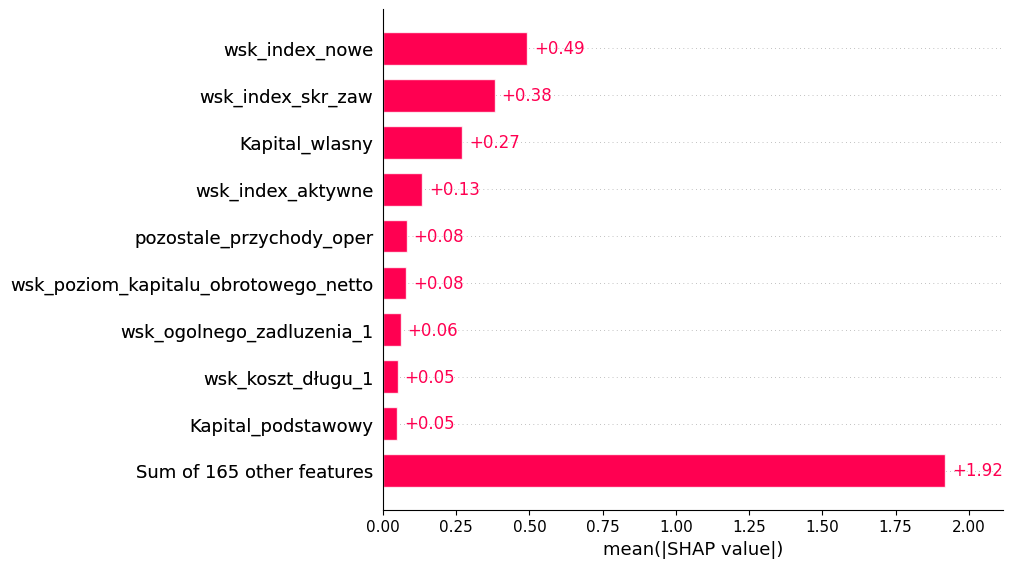

In [14]:
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=10)

Na podtawie powyższego wykresu shap barplot, największy wpłyyw na predykcje defaultu ma wsk_index_nowe, a zanim wsk_index_skr_zaw oraz kapitał własny.

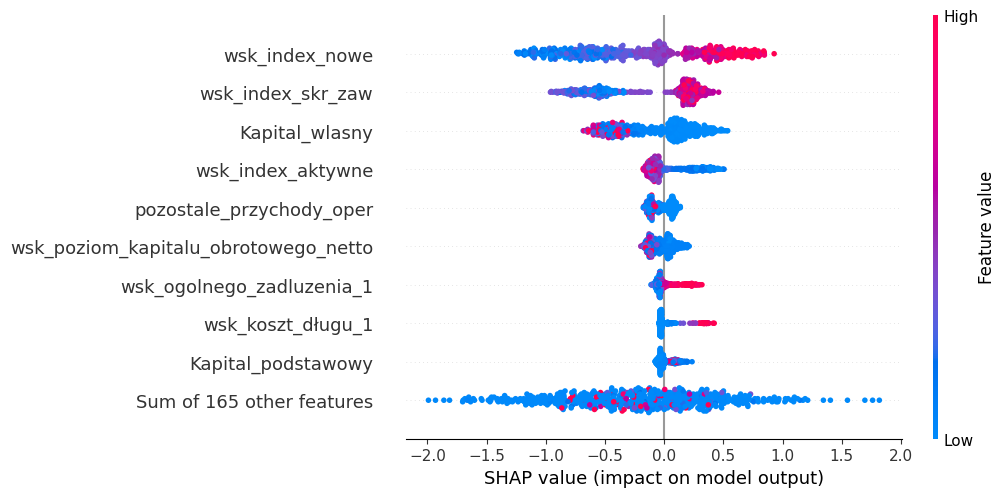

In [15]:
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=10)

Analiza powyższego wykresu wskazuje, że wysokie wartości wsk_index_nowe zwiększa przewidywane ryzyko defaultu, a niskie zmnniejsza.

<Figure size 800x500 with 0 Axes>

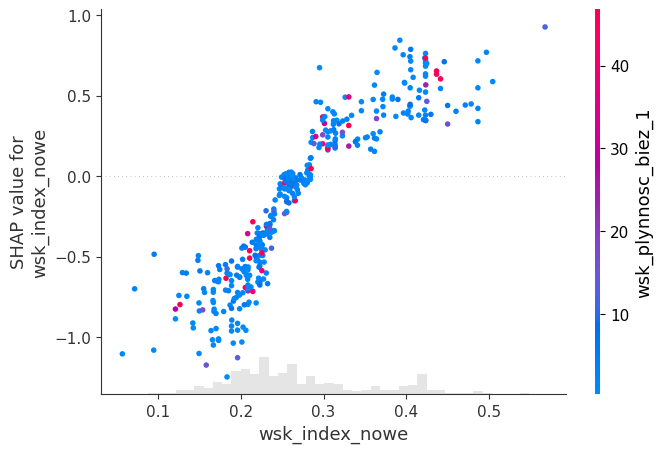

In [16]:
# Wykres dla pierwszej najważniejszej cechy
top_feature = clean_feature_names[np.abs(shap_values.values).mean(0).argmax()]
plt.figure(figsize=(8, 5))
shap.plots.scatter(shap_values[:, top_feature], color=shap_values)

## Wyjaśnienie lokalne dla firmy (id - 1784)

In [37]:
preprocessor = black_box.named_steps["preprocessor"]
xgb_model = black_box.named_steps["xgboost"]

X_train_prep = preprocessor.transform(X.replace([np.inf, -np.inf], np.nan))
X_test_prep = preprocessor.transform(X_test.replace([np.inf, -np.inf], np.nan))

X_train_prep = np.nan_to_num(np.asarray(X_train_prep, dtype=np.float64), nan=0.0)
X_test_prep = np.nan_to_num(np.asarray(X_test_prep, dtype=np.float64), nan=0.0)

raw_feature_names = list(preprocessor.get_feature_names_out())
clean_feature_names = [
    name.replace("remainder__", "").replace("categorical__", "") 
    for name in raw_feature_names
]


explainer_lime = LimeTabularExplainer(
    training_data=X_train_prep,
    feature_names=clean_feature_names,
    class_names=['Healthy', 'Default'],
    mode='classification',
    discretize_continuous=True,
    random_state=42
)

def predict_fn_prep(x_numpy):
    x_clean = np.nan_to_num(np.asarray(x_numpy, dtype=np.float64), nan=0.0)
    return xgb_model.predict_proba(x_clean)
def evaluate_lime_fidelity(instance_idx, label=1):
    exp_single = explainer_lime.explain_instance(
        data_row=X_test_prep[instance_idx],
        predict_fn=predict_fn_prep,
        num_features=10,
        num_samples=3000
    )
    r2 = exp_single.score
    
    xgb_pred = exp_single.predict_proba[label]
    lime_pred = exp_single.local_pred[0]
    diff = abs(xgb_pred - lime_pred)
    
    
    
    return {
        'Firma_ID': instance_idx,
        'XGBoost_Pred': xgb_pred,
        'LIME_Pred': lime_pred,
        'Roznica_Abs': diff,
        'R2_Fidelity': r2
    }

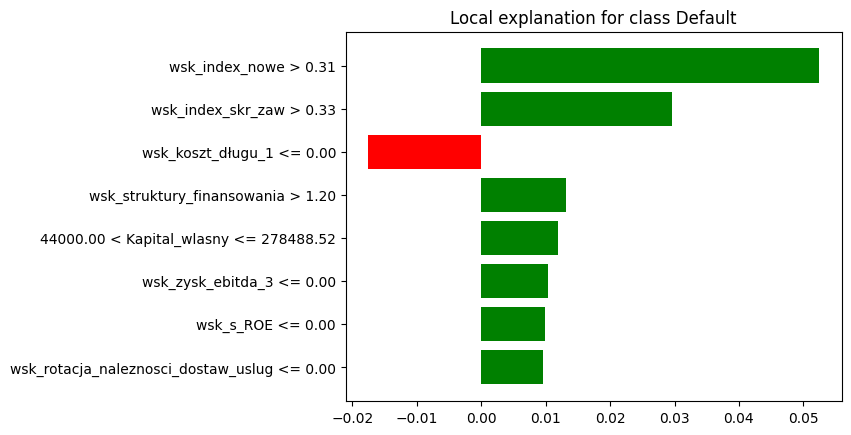

In [38]:
exp = explainer_lime.explain_instance(
    data_row=X_test_prep[0],
    predict_fn=predict_fn_prep,
    num_features=8)

fig = exp.as_pyplot_figure()
plt.show()

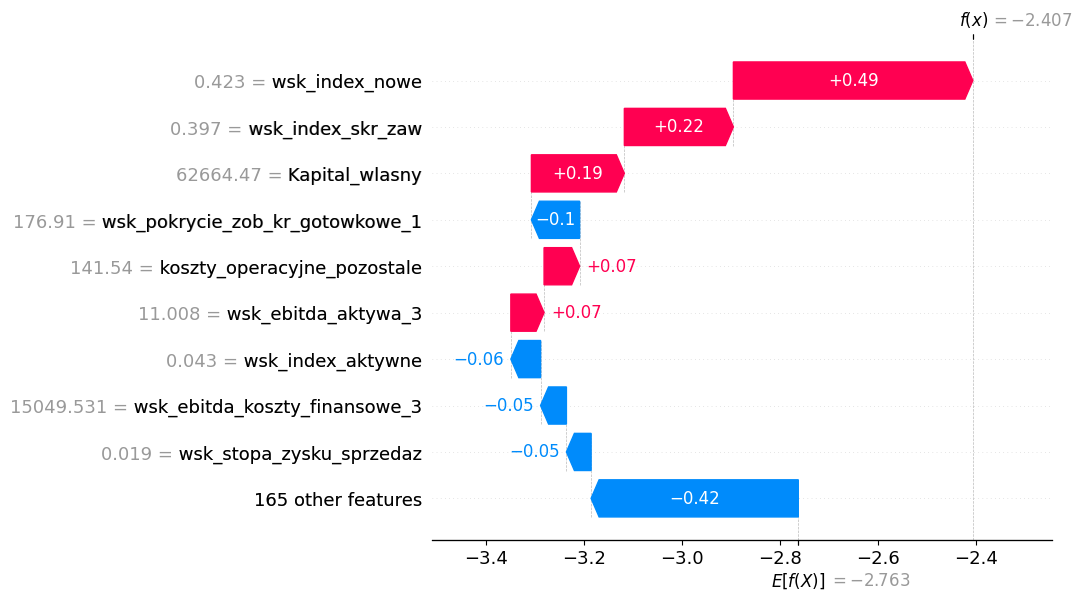

In [ ]:
plt.figure(figsize=(8, 6))
shap.plots.waterfall(shap_values[0])

### Porównanie lokalnego wyjaśnienia LIME oraz SHAP dla wybranej firmy:
Przedstawione wykresy przedtawiają lokalne wyjaśnienie predykcji wygenerowanej przez model XGBoost dla tej samej firmy metod interpretowalności: LIME oraz SHAP Waterfall.

Obie metody są zgodne co do dwóch najważniejszych czynników podwyższających ryzyko niewypłacalności. W obu przypadkach wsk_index_nowe jest to czynnikiem o największym dodatnim wpływie na predykcję ryzyka. W obu modelach stanowi drugi najważniejszy czynnik zwiększający ryzyko niewypłacalności to wsk_index_skr_zaw

In [50]:
print('Eksperyment wierności ')
wyniki = []
for idx in [0, 5, 12]:
    wyniki.append(evaluate_lime_fidelity(idx))

df_porownanie = pd.DataFrame(wyniki)
df_porownanie

Eksperyment wierności 


,Firma_ID,XGBoost_Pred,LIME_Pred,Roznica_Abs,R2_Fidelity
0,0,0.082642,0.146919,0.064277,0.206337
1,5,0.236889,0.178287,0.058603,0.241752
2,12,0.046839,0.148014,0.101175,0.295956


Otrzymane wyniki wskazują na niską wierność wyjaśnień LIME względem modelu XGBoost. Oznacza to, że prosta płaszczyzna liniowa LIME wyjaśnia niespełna $19–28\%$ zmienności zachowania modelu black-box w lokalnym otoczeniu badanych firm. 

In [51]:
def evaluate_lime_stability(instance_idx, n_runs=5):
    rankings = []
    for r in range(n_runs):
        exp_s = explainer_lime.explain_instance(
            data_row=X_test_prep[instance_idx],
            predict_fn=predict_fn_prep,
            num_features=5,
            num_samples=2000
        )
        rankings.append([item[0] for item in exp_s.as_list()])
    
    base = set(rankings[0])
    jaccards = [len(base.intersection(set(rk))) / len(base.union(set(rk))) for rk in rankings[1:]]
    mean_j = np.mean(jaccards)
    print(f"Firma #{instance_idx}, Średni Indeks Jaccarda (Top-5 Stability): {mean_j:.2%}")
    return mean_j

print(' Eksperyment stabilności (Stability - Jaccard)')
for k in [0, 5, 12]:
    evaluate_lime_stability(k)




 Eksperyment stabilności (Stability - Jaccard)
Firma #0, Średni Indeks Jaccarda (Top-5 Stability): 48.81%
Firma #5, Średni Indeks Jaccarda (Top-5 Stability): 60.71%
Firma #12, Średni Indeks Jaccarda (Top-5 Stability): 83.33%


Czynniki wpływające na stabilność: stosunkowo mało wybranych cech k =5 

Źródło niestabilności: losowegy algorytm próbkowania

In [52]:
# What-if
# Firma o podwyższonym ryzyku z zestawu testowego
target_firm_idx = 0
orig_row = X_test.iloc[target_firm_idx:target_firm_idx+1].copy()
initial_pd = black_box.predict_proba(orig_row)[0, 1]

print(f"What- if dla firmy danej firmy..")
print(f"Początkowe szacowane prawdopodobieństwo defaultu (PD): {initial_pd:.2%}")

# Wybieram biznesowo uzasadniony wskaźnik do modyfikacji
feature_to_change = 'Kapital_wlasny' if 'Kapital_wlasny' in orig_row.columns else X.columns[0]
current_val = orig_row[feature_to_change].values[0]

print(f"Modyfikowana zmienna: {feature_to_change} (Obecna wartość: {current_val:,.2f})")

target_pd = 0.04
success = False

for step in range(1, 40):
    test_row = orig_row.copy()
    # Zakładam poprawę wartości wskaźnika o +5% w każdym kroku
    new_val = current_val * (1 + step * 0.05) if current_val > 0 else current_val + (step * 10000)
    test_row[feature_to_change] = new_val
    
    new_pd = black_box.predict_proba(test_row)[0, 1]
    
    if new_pd <= target_pd:
        print(f"\n[SUKCES KONTRFAKTYCZNY]")
        print(f"Aby obniżyć ryzyko defaultu z {initial_pd:.2%} do {new_pd:.2%} (przejście do bezpiecznej klasy ratingowej):")
        print(f"Wartość '{feature_to_change}' musi wzrosnąć do {new_val:,.2f} (zmiana o +{step*5}%).")
        success = True
        break

if not success:
    print("\nZmiana pojedynczej zmiennej w założonym przedziale nie wystarczyła do osiągnięcia PD <= 4%.")

What- if dla firmy danej firmy..
Początkowe szacowane prawdopodobieństwo defaultu (PD): 7.48%
Modyfikowana zmienna: Kapital_wlasny (Obecna wartość: 62,664.47)

Zmiana pojedynczej zmiennej w założonym przedziale nie wystarczyła do osiągnięcia PD <= 4%.
